# 02 · Quanto ganha cada cargo, em cada nível

Edição mais recente (coletada de 20/10 a 22/12/2025), só quem mora no
Brasil, valores em **reais de novembro de 2025**.

**Como se mede:** a pesquisa dá a faixa salarial, não o valor. A mediana de
cada grupo é a **mediana agrupada** — acha a faixa onde a metade das
respostas é cruzada e interpola dentro dela (`salarios/estatistica.py`,
testada em salários simulados: erro abaixo de 3%). O intervalo de 95% sai de
500 reamostragens das respostas.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from salarios.estatistica import ic_bootstrap, mediana_agrupada
from salarios.graficos import NIVEIS, TINTA_2, MUDO, estilo, eixo_reais, reais
from salarios.ipca import fator

estilo()
df = pd.read_parquet("../dados/tratados/respostas.parquet")
d = df[(df["ano"] == 2025) & (df["situacao"] != "Fora do Brasil") & df["sal_min"].notna()].copy()
d["lo"], d["hi"] = d["sal_min"] * fator(2025), d["sal_max"] * fator(2025)
print(f"{len(d):,} respostas com salário; mediana geral {reais(mediana_agrupada(d.lo, d.hi))}")

3,161 respostas com salário; mediana geral R$ 10,6 mil


## Por família de cargo e nível

Grupos com menos de 20 respostas ficam de fora: o intervalo deles é largo
demais para dizer alguma coisa. "Sênior" aqui inclui quem marcou
"Especialista/Staff+", opção nova de 2025 (ver mais abaixo).

In [2]:
FAMILIAS = ["Engenheiro de ML", "Cientista de Dados", "Engenheiro / Arquiteto de Dados",
            "Desenvolvedor / Eng. de Software", "Analista de BI / Analytics Engineer",
            "Analista de Dados", "Analista de Negócios"]
MINIMO = 20


def resumo(g):
    if len(g) < MINIMO:
        return pd.Series({"n": len(g), "mediana": np.nan, "ic_baixo": np.nan, "ic_alto": np.nan})
    a, b = ic_bootstrap(g["lo"].to_numpy(), g["hi"].to_numpy(), n=500)
    return pd.Series({"n": len(g), "mediana": mediana_agrupada(g["lo"], g["hi"]), "ic_baixo": a, "ic_alto": b})


tab = (d[d["familia"].isin(FAMILIAS)]
       .groupby(["familia", "nivel_comparavel"], observed=True)
       .apply(resumo, include_groups=False)
       .reset_index())
tab["n"] = tab["n"].astype(int)
tab.pivot(index="familia", columns="nivel_comparavel", values="mediana").loc[FAMILIAS].round(-1)

nivel_comparavel,Júnior,Pleno,Sênior
familia,,,
Engenheiro de ML,4600.0,NaN,20280.0
Cientista de Dados,5670.0,9270.0,15520.0
Engenheiro / Arquiteto de Dados,4390.0,8920.0,15490.0
Desenvolvedor / Eng. de Software,3500.0,7500.0,14840.0
Analista de BI / Analytics Engineer,3610.0,6840.0,12230.0
Analista de Dados,3570.0,6700.0,10780.0
Analista de Negócios,3000.0,6400.0,10430.0


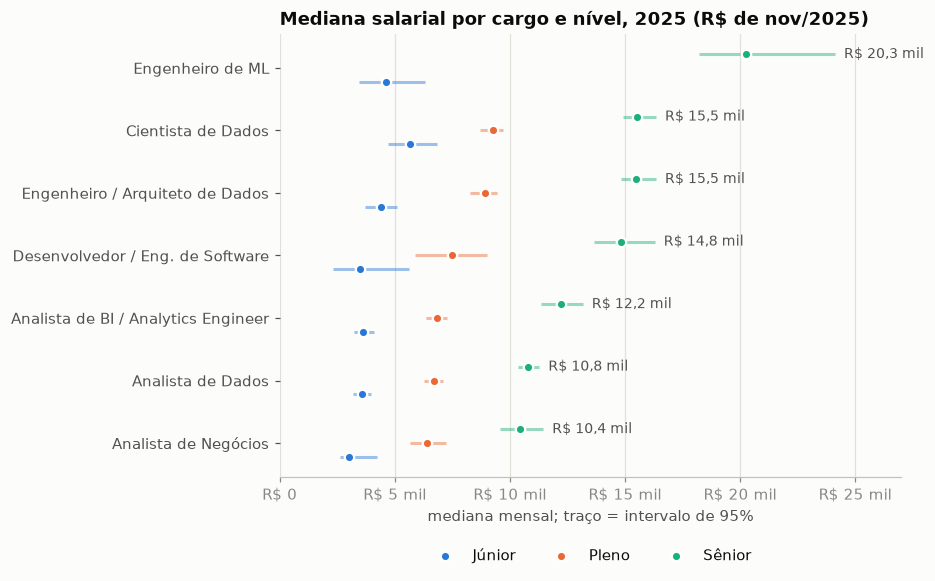

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ordem = (tab[tab["nivel_comparavel"] == "Sênior"].set_index("familia")["mediana"]
         .reindex(FAMILIAS).sort_values().index)
y = {f: i for i, f in enumerate(ordem)}
desloc = {"Júnior": -0.22, "Pleno": 0.0, "Sênior": 0.22}
for nivel, cor in NIVEIS.items():
    t = tab[(tab["nivel_comparavel"] == nivel) & tab["mediana"].notna()]
    yy = [y[f] + desloc[nivel] for f in t["familia"]]
    ax.hlines(yy, t["ic_baixo"], t["ic_alto"], color=cor, linewidth=2, alpha=0.45)
    ax.scatter(t["mediana"], yy, color=cor, s=38, zorder=3, label=nivel, edgecolor="white", linewidth=1.5)
# rótulo seletivo: só o sênior, que é o que ordena o gráfico
for _, r in tab[(tab["nivel_comparavel"] == "Sênior") & tab["mediana"].notna()].iterrows():
    ax.annotate(reais(r["mediana"]), (r["ic_alto"], y[r["familia"]] + 0.22), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=TINTA_2)
ax.set_yticks(range(len(ordem)), ordem)
ax.grid(axis="y", visible=False)
eixo_reais(ax)
ax.set_xlim(0, 27000)
ax.set_title("Mediana salarial por cargo e nível, 2025 (R$ de nov/2025)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncols=3)
ax.set_xlabel("mediana mensal; traço = intervalo de 95%")
plt.tight_layout()

**Leitura:**

- **No sênior, engenharia e ciência de dados empatam:** R$ 15,5 mil de
  mediana nas duas famílias, com intervalos que se sobrepõem quase inteiros.
  A diferença entre elas está no começo: cientista júnior tem mediana de
  R$ 5,7 mil, engenheiro júnior de R$ 4,4 mil.
- **Engenheiro de ML sênior tem a maior mediana (R$ 20,3 mil)**, mas com 67
  respostas e intervalo de R$ 18 a 24 mil. O pleno não aparece: tem 16
  respostas, abaixo do mínimo de 20.
- **Analista de dados e de negócios ficam abaixo no sênior** (R$ 10,8 e
  10,4 mil): a distância para engenharia e ciência abre com a senioridade.
  No júnior, analista de dados e engenheiro de dados ficam a R$ 0,8 mil um
  do outro (R$ 3,6 e 4,4 mil); no sênior, a R$ 4,7 mil.

## Quanto vale subir de nível

In [4]:
piv = tab.pivot(index="familia", columns="nivel_comparavel", values="mediana").loc[FAMILIAS]
saltos = pd.DataFrame({
    "Júnior → Pleno": piv["Pleno"] / piv["Júnior"],
    "Pleno → Sênior": piv["Sênior"] / piv["Pleno"],
    "Júnior → Sênior": piv["Sênior"] / piv["Júnior"],
}).round(2)
saltos

,Júnior → Pleno,Pleno → Sênior,Júnior → Sênior
familia,,,
Engenheiro de ML,NaN,NaN,4.41
Cientista de Dados,1.64,1.68,2.74
Engenheiro / Arquiteto de Dados,2.03,1.74,3.53
Desenvolvedor / Eng. de Software,2.14,1.98,4.24
Analista de BI / Analytics Engineer,1.89,1.79,3.39
Analista de Dados,1.87,1.61,3.02
Analista de Negócios,2.13,1.63,3.48


Do júnior ao sênior a mediana multiplica por 2,7 (cientista) a 3,5
(engenheiro de dados) nas famílias com mais respostas. Desenvolvedor (4,2×)
e engenheiro de ML (4,4×) passam disso, mas o júnior deles tem só 24 e 21
respostas. O salto do júnior para o pleno (1,6× a 2,1×) é maior que o do
pleno para o sênior (1,6× a 2,0×) em todas as famílias menos uma: cientista
de dados, cujo júnior já começa mais alto.

## Staff+ e gestores

A edição de 2025 separou "Especialista/Staff+" de Sênior. Juntos, os dois
escondem uma diferença grande:

In [5]:
REAIS = ["mediana", "ic_baixo", "ic_alto"]


def arredondar(t):
    """Arredonda só os valores em reais; a contagem fica exata."""
    return t.assign(n=t["n"].astype(int), **{c: t[c].round(-1) for c in REAIS})


arredondar(pd.DataFrame({
    nivel: resumo(d[d["nivel"] == nivel])
    for nivel in ["Júnior", "Pleno", "Sênior", "Especialista/Staff+"]
}).T)

,n,mediana,ic_baixo,ic_alto
Júnior,515,3480.0,3230.0,3720.0
Pleno,761,7460.0,7240.0,7740.0
Sênior,833,12130.0,11660.0,12640.0
Especialista/Staff+,343,17240.0,16350.0,18050.0


In [6]:
g = d[d["familia"] == "Gestor"]
gestores = g.groupby("gestor_nivel", observed=True).apply(resumo, include_groups=False)
arredondar(gestores).sort_values("mediana", ascending=False)

,n,mediana,ic_baixo,ic_alto
gestor_nivel,,,,
Gerente/Head/Diretor/VP,308,23080.0,21730.0,24400.0
Sócio ou C-level,82,18000.0,14790.0,23130.0
Team Leader/Tech Leader,98,15810.0,14360.0,17640.0
Supervisor/Coordenador,221,14350.0,13320.0,15330.0


Quem marcou "Especialista/Staff+" tem mediana de R$ 17,2 mil, 42% acima de
quem marcou Sênior (R$ 12,1 mil). Antes de 2025 os dois grupos respondiam
"Sênior"; por isso a comparação entre anos usa o nível comparável, que junta
os dois.

Entre gestores, gerente/head/diretor/VP tem mediana de R$ 23,1 mil, a maior
de todos os grupos com amostra suficiente. Supervisor ou coordenador
(R$ 14,3 mil) ganha menos que o cientista ou engenheiro sênior.

## Tabela completa

In [7]:
arredondar(tab).sort_values(["familia", "nivel_comparavel"])

,familia,nivel_comparavel,n,mediana,ic_baixo,ic_alto
0,Analista de BI / Analytics Engineer,Júnior,68,3610.0,3240.0,4090.0
1,Analista de BI / Analytics Engineer,Pleno,122,6840.0,6340.0,7270.0
2,Analista de BI / Analytics Engineer,Sênior,155,12230.0,11340.0,13160.0
3,Analista de Dados,Júnior,144,3570.0,3170.0,3960.0
4,Analista de Dados,Pleno,205,6700.0,6260.0,7120.0
5,Analista de Dados,Sênior,239,10780.0,10330.0,11270.0
6,Analista de Negócios,Júnior,22,3000.0,2620.0,4240.0
7,Analista de Negócios,Pleno,52,6400.0,5660.0,7210.0
8,Analista de Negócios,Sênior,66,10430.0,9560.0,11440.0
9,Cientista de Dados,Júnior,65,5670.0,4690.0,6830.0
